Mode=mcx | Stage=full | wavelengths=[730, 850, 940] | sources=15 | detectors=50 | 5,000,000 photons per source
  730 nm: source 1/15; photons=5,000,000
nphoton: 5e+06
tstart: 0
tstep: 5e-09
tend: 5e-09
maxdetphoton: 1e+06
isreflect: 1
issrcfrom0: 1
unitinmm: 0.25
issaveexit: 0
issavedet: 1
issaveseed: 1

GPU=1 (NVIDIA GeForce RTX 4060 Laptop GPU) threadph=50 extra=84800 np=5000000 nthread=98304 maxgate=1 repetition=1
initializing streams ...	init complete : 2 ms
requesting shared memory: 3072 bytes
launching MCX simulation for time window [0.00e+00ns 5.00e+00ns] ...
simulation run# 1 ... 
kernel complete:  	485 ms
retrieving fields ... 	WARNING: the detected photon number is more than what your have specified (1174831 > 1000000), please use the -H option to specify a greater number
transfer complete:	513 ms
normalizing raw data ...	source 1, normalization factor alpha=640.000000
data normalization complete : 520 ms
simulated 5000000 photons (5000000) with 98304 threads (repeat x1)
MCX 

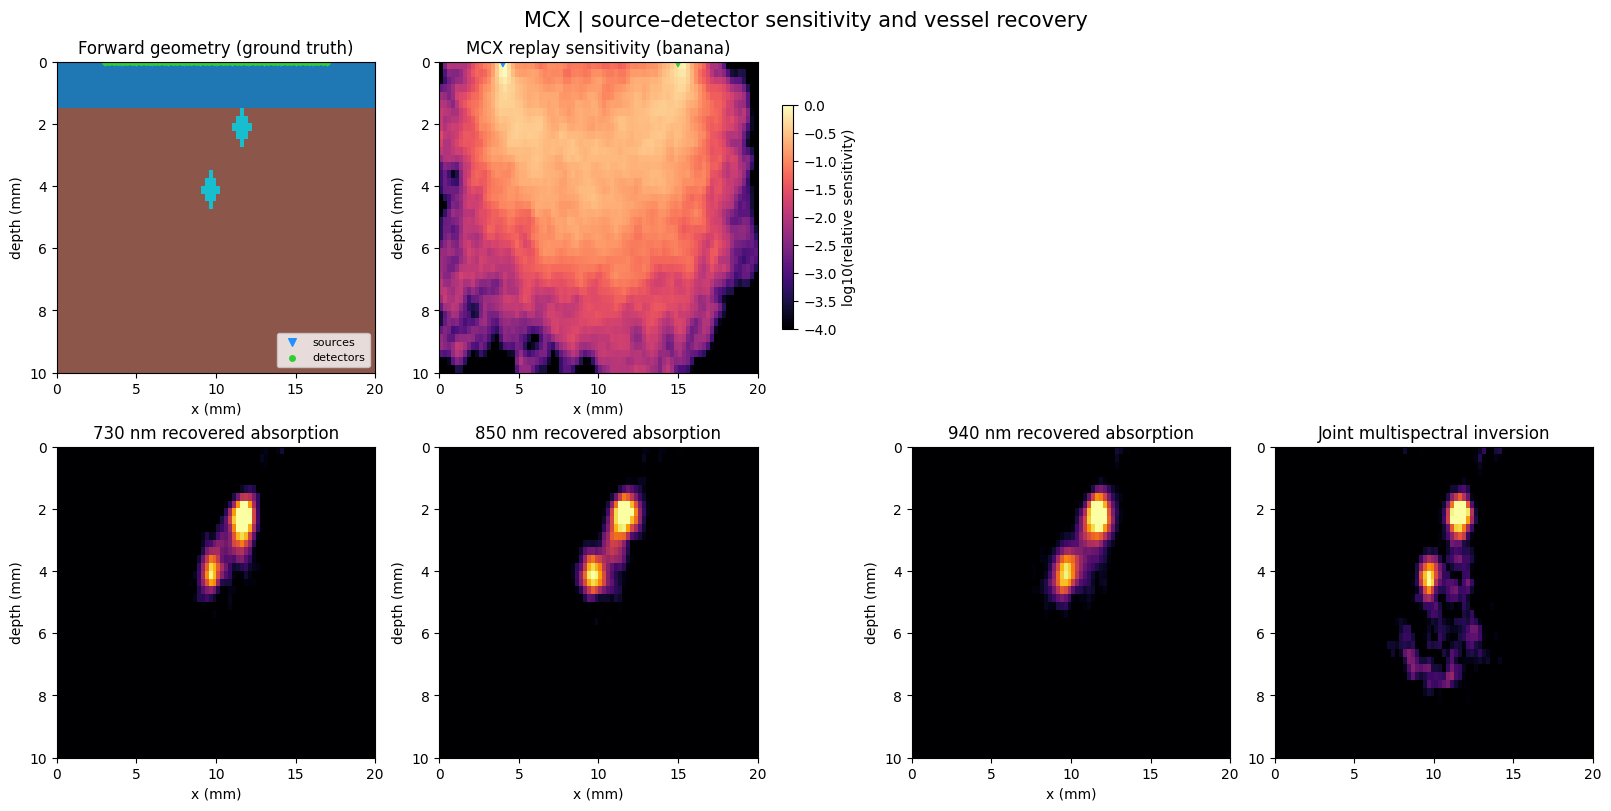

Saved vein_output/vein_reconstruction.png


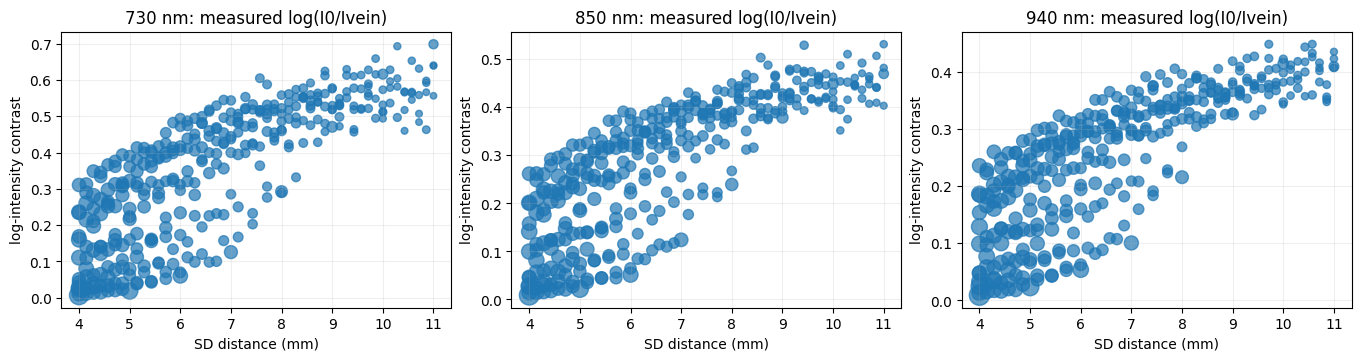

Saved vein_output/measurement_diagnostics.png


TypeError: unsupported format string passed to list.__format__

In [9]:
"""Vein reconstruction: MCX photon replay and nonnegative absorption tomography.

Jupyter notebook edition — paste this entire file into ONE notebook cell.
Requires numpy, scipy and matplotlib; real MCX mode additionally needs pmcx
and a working GPU backend.
The self-test uses illustrative diffusion kernels (NOT an MCX simulation).
"""

import copy
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

# ================================================================
# NOTEBOOK SETTINGS — edit these and run this cell
# ================================================================
RUN_MODE = 'mcx'          # 'mcx' = real photon transport; 'self_test' = no GPU
RUN_STAGE = 'full'       # 'smoke' -> 'medium' -> 'full' (three wavelengths)
OUTPUT_DIR = Path('vein_output')
SHOW_PLOTS_INLINE = True

CFG = {
    'nx': 80, 'ny': 80, 'nz': 40,
    'voxel_size_mm': 0.25,
    'subcut_start_vox': 6,
    'vein_x_mm': [11.5, 9.5], 'vein_z_mm': [2.0, 4.0], 'vein_radius_mm': [0.5, 0.5],
    'src_x_vox_range': (12, 68),
    'det_x_vox_range': (12, 68),
    'det_radius_vox': 2.5,        # 0.625 mm aperture; larger than original
    'sd_min_mm': 4.0,           # sample deeper than 2.5 mm separations
    'sd_max_mm': 11.0,
    'gpuid': 1,
    'tstart': 0.0, 'tend': 5e-9, 'tstep': 5e-9,
    'maxdetphoton': 1000000,
    'min_detected': {'smoke': 5, 'medium': 30, 'full': 100},
    'stages': {
        'smoke':  {'n_sources': 3, 'n_detectors': 7,  'nphoton': 100000,  'wavelengths_nm': [850]},
        'medium': {'n_sources': 5, 'n_detectors': 11, 'nphoton': 700000,  'wavelengths_nm': [850]},
        'full':   {'n_sources': 15, 'n_detectors': 50, 'nphoton': 5000000, 'wavelengths_nm': [730, 850, 940]},
    },
    # Optical properties: [mu_a (mm^-1), mu_s (mm^-1), g, n].
    # For an absorption-only inverse example, the reference vessel compartment has
    # IDENTICAL optical properties to surrounding fat. The target differs ONLY
    # in absorption. This gives matched scattering trajectories, enabling exact
    # perturbation-MC reweighting of each detected photon.
    'prop_by_wl': {
        730: np.array([[0,0,1,1], [.040,13.5,.85,1.4], [.020,9.0,.85,1.4], [.60,12.0,.95,1.38]], dtype=float),
        850: np.array([[0,0,1,1], [.030,12.0,.85,1.4], [.015,8.0,.85,1.4], [.45,10.0,.95,1.38]], dtype=float),
        940: np.array([[0,0,1,1], [.025,11.0,.85,1.4], [.012,7.5,.85,1.4], [.38,9.0,.95,1.38]], dtype=float),
    },
    'inverse': {
        'smooth_strength': .025,   # quadratic spatial regularization
        'ridge_strength':  .003,   # weak Tikhonov regularization
        'sparsity_strength': .007, # L1 penalty promotes compact absorption changes
        'max_iter': 850,
        'depth_compensation': 0.35, # only using J sensitivity, never true vein position
        'max_compensation': 10.0,
        'max_absorption_fraction': 1.0,
    },
}


def layout(cfg, stage):
    cfg = copy.deepcopy(cfg)
    cfg['stage'] = stage
    cfg.update(cfg['stages'][stage])
    cfg['y_center_vox'] = cfg['ny'] // 2
    sx = np.linspace(*cfg['src_x_vox_range'], cfg['n_sources'])
    dx = np.linspace(*cfg['det_x_vox_range'], cfg['n_detectors'])
    dp = np.column_stack((dx, np.full_like(dx, cfg['y_center_vox']),
                          np.zeros_like(dx), np.full_like(dx, cfg['det_radius_vox'])))
    cfg['sources_x_vox'] = sx
    cfg['detectors_x_vox'] = dx
    cfg['detpos'] = dp
    return cfg


def make_labeled_volume(cfg):
    """Compartment 3 identifies the true vein only in the DATA GENERATOR."""
    v = np.ones((cfg['nx'], cfg['ny'], cfg['nz']), dtype=np.uint8)
    v[:, :, cfg['subcut_start_vox']:] = 2
    u = cfg['voxel_size_mm']
    x = np.arange(cfg['nx'])[:, None, None] * u
    z = np.arange(cfg['nz'])[None, None, :] * u
    mask = np.zeros((cfg['nx'], 1, cfg['nz']), dtype=bool)
    for vx, vz, vr in zip(cfg['vein_x_mm'], cfg['vein_z_mm'], cfg['vein_radius_mm']):
        mask |= (x - vx)**2 + (z - vz)**2 <= vr**2
    v[np.broadcast_to(mask, v.shape)] = 3
    return v


def baseline_and_target_properties(prop):
    """Match only the absorption contrast to the unknown; exclude scattering confounds."""
    target = np.asarray(prop, dtype=float).copy()
    baseline = target.copy()
    baseline[3, :] = baseline[2, :]  # identical fat-like optical properties
    target[3, 1:] = baseline[3, 1:]  # target vein differs only in absorption
    return baseline, target


def detected_photons(detp, baseline_mua, target_mua, voxel_mm):
    """MCX DP format: row 0=detector ID; rows 1:1+nmed=path lengths (voxel units)."""
    d = np.asarray(detp)
    nmed = len(baseline_mua)
    if d.ndim != 2 or d.shape[0] < nmed + 1:
        raise ValueError(f'Expected MCX detp with at least {nmed+1} rows (DP), got {d.shape}')
    ids = np.asarray(d[0], dtype=np.int32)
    ppath_mm = np.asarray(d[1:1+nmed].T, dtype=np.float64) * voxel_mm
    if ppath_mm.size == 0:
        return ids, np.zeros(0), np.zeros(0)
    w0 = np.exp(-ppath_mm @ np.asarray(baseline_mua))
    w1 = np.exp(-ppath_mm @ np.asarray(target_mua))
    return ids, w0, w1


def run_forward(pmcx, base_cfg, cfg, sx_vox, seed):
    c = {
        'nphoton': cfg['nphoton'],
        'vol': base_cfg['volume'],
        'prop': base_cfg['prop'],
        'unitinmm': cfg['voxel_size_mm'],
        'srcpos': [float(sx_vox), float(cfg['y_center_vox']), 0.],
        'srcdir': [0., 0., 1.],
        'detpos': cfg['detpos'],
        'tstart': cfg['tstart'], 'tend': cfg['tend'], 'tstep': cfg['tstep'],
        'gpuid': cfg['gpuid'],
        'seed': int(seed),
        'issrcfrom0': 1,
        'isreflect': 1,
        'issavedet': 1,
        'issaveseed': 1,
        'issaveexit': 0,
        'savedetflag': 'DP',
        'maxdetphoton': cfg['maxdetphoton'],
        'outputtype': 'flux',
        'flog': 0,
    }
    res = pmcx.run(c)
    if 'detp' not in res or 'seeds' not in res:
        raise RuntimeError('MCX must return detected photon histories and replay seeds. Check issavedet/issaveseed.')
    return c, res


def replay_all_detector_sensitivities(pmcx, forward_cfg, forward_result, cfg):
    """Replay the BASELINE photons to get dlog(I)/dmu_a per detector.

    Returns jac_raw: [nx, ny, nz, ndet]; MCX values have path lengths
    expressed in voxels and are unnormalized here. Convert with voxel_size_mm
    and normalize by baseline detector intensity outside this function.
    """
    n = cfg['n_detectors']
    expected = (cfg['nx'], cfg['ny'], cfg['nz'])
    cc = dict(forward_cfg)
    cc.update({'seed': forward_result['seeds'], 'detphotons': forward_result['detp'],
               'outputtype': 'jacobian', 'replaydet': -1, 'isnormalized': 0,
               'issave2pt': 1, 'issavedet': 0, 'issaveseed': 0})
    try:
        r = pmcx.run(cc)
        raw = np.asarray(r['flux'])
        if raw.shape[:3] != expected or raw.size != np.prod(expected) * n:
            raise RuntimeError(f'Unexpected replay output shape {raw.shape} for {n} detectors')
        return np.asarray(raw.reshape((*expected, n)), dtype=np.float64)
    except Exception as e:
        print(f'    all-detector replay unavailable ({e}); falling back to individual detectors')
        maps = np.empty((*expected, n), dtype=np.float64)
        for did in range(1, n + 1):
            one = dict(cc, replaydet=did)
            r = pmcx.run(one)
            arr = np.asarray(r['flux'])
            if arr.size != np.prod(expected):
                raise RuntimeError(f'Unexpected replay jacobian shape for det {did}: {arr.shape}')
            maps[:, :, :, did-1] = arr.reshape(expected)
        return maps


def simulate_one_wavelength(pmcx, cfg, wl, volume):
    baseline, target = baseline_and_target_properties(cfg['prop_by_wl'][wl])
    model = {'volume': volume, 'prop': baseline}
    J, measured, pairs, detected = [], [], [], []
    example = None
    voxel = cfg['voxel_size_mm']
    delta_mua = float(target[3, 0] - baseline[3, 0])
    if delta_mua <= 0:
        raise ValueError('Blood absorption must exceed fat absorption for this nonnegative model')

    for i, sx in enumerate(cfg['sources_x_vox']):
        print(f'  {wl} nm: source {i+1}/{cfg["n_sources"]}; photons={cfg["nphoton"]:,}', flush=True)
        fcfg, base = run_forward(pmcx, model, cfg, sx, seed=3721 + 101*i + wl*7)
        ids, w0, w1 = detected_photons(base['detp'], baseline[1:, 0], target[1:, 0], voxel)
        if ids.size == 0:
            print('    No detected photons for this source')
            continue
        jac_all = replay_all_detector_sensitivities(pmcx, fcfg, base, cfg)

        for j, dx in enumerate(cfg['detectors_x_vox']):
            sep = abs(dx-sx)*voxel
            if not cfg['sd_min_mm'] <= sep <= cfg['sd_max_mm']:
                continue
            selected = ids == j+1   # MCX IDs are 1-based
            count = int(np.count_nonzero(selected))
            if count < cfg['min_detected'][cfg['stage']]:
                continue
            I0 = float(w0[selected].sum())
            I1 = float(w1[selected].sum())
            if I0 < 1e-25 or I1 < 1e-25:
                continue
            log_ratio = np.log(I0 / I1)       # NO mean-subtraction or per-WL normalization
            # The unnormalized replay jacobian is the sum of weighted pathlengths.
            # Integrate over all Y because the vein is modeled as a Y-axis cylinder.
            j_xz = (np.sum(jac_all[:, :, :, j], axis=1) * voxel) / I0
            j_row = (j_xz * delta_mua).reshape(-1)
            if not np.isfinite(j_row).all() or max(j_row) <= 0:
                continue
            J.append(j_row)
            measured.append(log_ratio)
            pairs.append((sx*voxel, dx*voxel, sep))
            detected.append(count)
            # A centered long SD pair is useful to show the banana for illustration.
            center = cfg['nx'] * voxel / 2
            score = sep - 0.1*abs((sx+dx)*voxel/2-center)
            if example is None or score > example['score']:
                example = {'J_xz': j_xz.copy(), 'sx_mm': sx*voxel,
                           'dx_mm': dx*voxel, 'score': score}
        del jac_all

    if not J:
        raise RuntimeError(f'No usable detector pairs at {wl} nm. Increase nphoton, detector aperture '
                           f'or reduce the min_detected threshold ({cfg["min_detected"][cfg["stage"]]}).')
    J = np.asarray(J)
    y = np.asarray(measured)
    pairs = np.asarray(pairs)
    detected = np.asarray(detected)
    print(f'  {wl} nm: {len(y)} usable pairs, detected photons/pair '
          f'[{detected.min()}..{detected.max()}], log contrast '
          f'[{y.min():.3g}..{y.max():.3g}].')
    return {'wl': wl, 'J': J, 'y': y, 'pairs': pairs, 'counts': detected,
            'example': example}


def spatial_laplacian(x, nx, nz):
    """Positive semi-definite Neumann-boundary discrete Laplacian L.T @ L x.

    Reconstruct image in x-major, z-minor order: reshape(nx,nz).
    """
    u = x.reshape(nx, nz)
    out = np.zeros_like(u)
    d = u[1:, :] - u[:-1, :]
    out[1:, :] += d
    out[:-1, :] -= d
    d = u[:, 1:] - u[:, :-1]
    out[:, 1:] += d
    out[:, :-1] -= d
    return out.reshape(-1)


def solve_inverse(J, y, cfg, max_iter=None):
    """Projected proximal-gradient with L1 sparsity, ridge and spatial smoothness.

    Uses only MCX-computed J and measured y, NOT vein_x_mm or vein_z_mm.
    """
    J = np.asarray(J, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)
    nx, nz = cfg['nx'], cfg['nz']
    n = nx*nz
    if J.ndim != 2 or J.shape[1] != n or J.shape[0] != y.size:
        raise ValueError(f'Inconsistent inverse sizes J={J.shape}, y={y.shape}, grid={(nx,nz)}')
    inv = cfg['inverse']
    # A bounded sensitivity-based reparameterization can reduce near-surface bias.
    sens = np.sqrt(np.sum(J**2, axis=0))
    inside = sens[sens > sens.max()*1e-4]
    reference = np.percentile(inside, 75) if inside.size else 1.0
    sens_clip = np.maximum(sens, reference / (inv['max_compensation'] ** (1/inv['depth_compensation'])))
    compensation = (reference / sens_clip) ** inv['depth_compensation']
    compensation = np.clip(compensation, 1.0/inv['max_compensation'], inv['max_compensation'])
    # Low sensitivity columns are not simply promoted to arbitrary deep noise; at
    # very low sensitivity no observation is possible, so suppress them.
    compensation[sens < sens.max()*3e-5] = 0.0
    Ap = J * compensation[np.newaxis, :]
    scale = max(np.max(np.linalg.norm(Ap, axis=1)), 1e-10)
    A = Ap / scale
    b = y / scale
    # objective 0.5||A u-b||^2 + ridge/2||u||^2
    #           + smooth/2||grad u||^2 + l1*sum(u), 0<=comp*u<=1
    ridge = inv['ridge_strength']
    smooth = inv['smooth_strength']
    l1 = inv['sparsity_strength']
    # Power iteration for norm(A)^2, avoiding 3200x3200 normal equations.
    q = np.ones(n, dtype=float) / np.sqrt(n)
    for _ in range(45):
        q = A.T @ (A @ q)
        q /= max(np.linalg.norm(q), 1e-15)
    lipschitz = np.linalg.norm(A @ q)**2 + ridge + smooth*8.0
    step = 0.90 / max(lipschitz, 1e-10)
    u = np.zeros(n)
    mom = u.copy()
    t = 1.0
    max_n = max_iter or inv['max_iter']
    for k in range(max_n):
        grad = A.T @ (A @ mom - b) + ridge*mom + smooth*spatial_laplacian(mom, nx, nz)
        next_u = np.maximum(0.0, mom - step*grad - step*l1)
        cap = inv['max_absorption_fraction'] / np.maximum(compensation, 1e-12)
        next_u = np.minimum(next_u, cap)
        # Standard FISTA extrapolation for the smooth term + nonnegative L1 prox.
        t_new = (1 + np.sqrt(1+4*t*t))/2
        extrap = next_u + ((t-1)/t_new)*(next_u-u)
        if k > 30 and np.linalg.norm(next_u-u) < 1e-7*max(1.0, np.linalg.norm(u)):
            u = next_u
            break
        u, mom, t = next_u, extrap, t_new
    f = (u*compensation).reshape(nx, nz).T
    print(f'    inverse: {k+1} iterations, reconstruction max={f.max():.3g}; '
          f'measurement relative RMSE={np.linalg.norm(J @ f.T.reshape(-1)-y)/max(np.linalg.norm(y),1e-12):.3f}')
    return f


def display_figures(cfg, results, recon_maps, fused, outdir, title_prefix='MCX'):
    outdir.mkdir(parents=True, exist_ok=True)
    u = cfg['voxel_size_mm']
    xmax, zmax = cfg['nx']*u, cfg['nz']*u
    imextent = [0, xmax, zmax, 0]
    ncols = len(results) + 1
    fig, axes = plt.subplots(2, max(2,ncols), figsize=(4.0*max(2,ncols), 8),
                             squeeze=False, constrained_layout=True)
    vol = make_labeled_volume(cfg)
    axes[0,0].imshow(vol[:, cfg['y_center_vox'], :].T, extent=imextent, aspect='auto',
                     interpolation='nearest', cmap='tab10', vmin=1, vmax=3)
    axes[0,0].set_title('Forward geometry (ground truth)')
    axes[0,0].scatter(cfg['sources_x_vox']*u, np.zeros(cfg['n_sources']),
                       marker='v', s=30, c='dodgerblue', label='sources')
    axes[0,0].scatter(cfg['detectors_x_vox']*u, np.zeros(cfg['n_detectors']),
                       marker='o', s=16, c='limegreen', label='detectors')
    axes[0,0].legend(fontsize=8, loc='lower right')
    for ai in (axes[0,0],):
        ai.set_xlabel('x (mm)'); ai.set_ylabel('depth (mm)')

    # Banana plot: a true detected-photon pathlength sensitivity, not a Gaussian.
    ex = results[len(results)//2]['example']
    bmap = ex['J_xz'].T
    bmap = gaussian_filter(np.maximum(bmap,0), .65)
    bmap = bmap / max(bmap.max(), 1e-20)
    hm = axes[0,1].imshow(np.log10(np.maximum(bmap, 1e-5)), extent=imextent,
                            aspect='auto', cmap='magma', vmin=-4, vmax=0)
    axes[0,1].scatter([ex['sx_mm'], ex['dx_mm']], [0.,0.],
                        c=['dodgerblue','limegreen'], s=55, marker='v')
    axes[0,1].set_title(('MCX replay sensitivity' if title_prefix == 'MCX'
                         else 'Illustrative diffusion sensitivity') + ' (banana)')
    axes[0,1].set_xlabel('x (mm)'); axes[0,1].set_ylabel('depth (mm)')
    fig.colorbar(hm, ax=axes[0,1], shrink=.72, label='log10(relative sensitivity)')
    for ax in axes[0,2:]:
        ax.axis('off')

    for i, (r, recon) in enumerate(zip(results,recon_maps)):
        ax = axes[1,i]
        ax.imshow(recon, extent=imextent, cmap='inferno', aspect='auto', vmin=0,
                  vmax=max(float(np.percentile(recon, 99.7)), float(recon.max())*.4, 1e-8))
        ax.set_title(f'{r["wl"]} nm recovered absorption')
        ax.set_xlabel('x (mm)'); ax.set_ylabel('depth (mm)')
    if len(results) == 1:
        ax = axes[1,1]
        ax.imshow(fused, extent=imextent, cmap='inferno', aspect='auto', vmin=0,
                  vmax=max(float(np.percentile(fused,99.7)), float(fused.max())*.4,1e-8))
        ax.set_title('Reconstruction (same as 850 nm)')
    else:
        ax = axes[1,len(results)]
        ax.imshow(fused, extent=imextent, cmap='inferno', aspect='auto', vmin=0,
                  vmax=max(float(np.percentile(fused,99.7)), float(fused.max())*.4,1e-8))
        ax.set_title('Joint multispectral inversion')
    for ax in axes[1,len(results)+1:]:
        ax.axis('off')
    fig.suptitle(title_prefix + ' | source–detector sensitivity and vessel recovery', fontsize=15)
    outfile = outdir / 'vein_reconstruction.png'
    fig.savefig(outfile, dpi=160)
    if SHOW_PLOTS_INLINE:
        plt.show()
    else:
        plt.close(fig)
    print('Saved', outfile)

    fig, axs = plt.subplots(1, len(results), figsize=(4.5*len(results), 3.5), squeeze=False,
                            constrained_layout=True)
    for ax, r in zip(axs[0], results):
        ss = r['pairs'][:,2]
        ax.scatter(ss, r['y'], s=np.sqrt(r['counts'])*2, alpha=.7)
        ax.set(title=f'{r["wl"]} nm: measured log(I0/Ivein)', xlabel='SD distance (mm)',
               ylabel='log-intensity contrast')
        ax.grid(alpha=.2)
    outfile=outdir/'measurement_diagnostics.png'
    fig.savefig(outfile,dpi=160)
    if SHOW_PLOTS_INLINE:
        plt.show()
    else:
        plt.close(fig)
    print('Saved', outfile)


def real_mcx_run(cfg, output_dir):
    try:
        import pmcx
    except ImportError as e:
        raise RuntimeError('pmcx is not installed; install a GPU-enabled pmcx/pmcxcl backend. '
                           'Set RUN_MODE to self_test to test the inversion independently of GPU.') from e
    vol = make_labeled_volume(cfg)
    results = []
    for wl in cfg['wavelengths_nm']:
        results.append(simulate_one_wavelength(pmcx, cfg, wl, vol))
    recon = []
    for r in results:
        print(f'Solving inverse for {r["wl"]} nm ...')
        recon.append(solve_inverse(r['J'],r['y'],cfg))
    if len(results) == 1:
        fused = recon[0]
    else:
        J = np.vstack([r['J'] for r in results])
        y = np.concatenate([r['y'] for r in results])
        print('Solving physically coupled multi-wavelength inverse ...')
        fused = solve_inverse(J,y,cfg)
    display_figures(cfg, results, recon, fused, output_dir)
    peak = np.unravel_index(np.argmax(fused), fused.shape)
    print(f'Joint reconstruction peak (x, depth) = ({peak[1]*cfg["voxel_size_mm"]:.2f}, '
          f'{peak[0]*cfg["voxel_size_mm"]:.2f}) mm; ground truth (not used in inverse) = '
          f'({cfg["vein_x_mm"]:.2f}, {cfg["vein_z_mm"]:.2f}) mm')
    np.savez_compressed(output_dir / 'mcx_reconstruction_data.npz',
                        wavelengths_nm=np.asarray(cfg['wavelengths_nm']), fused=fused,
                        **{f'rec_{r["wl"]}': f for r,f in zip(results,recon)})


def self_test(cfg, outdir):
    """Validate algebra with an analytic diffusion-inspired surrogate; NO MCX physics claimed."""
    rng = np.random.default_rng(7)
    nx,nz=cfg['nx'],cfg['nz']
    voxel=cfg['voxel_size_mm']
    xx=np.arange(nx)*voxel
    zz=np.arange(nz)*voxel
    X,Z=np.meshgrid(xx,zz,indexing='ij')
    gt = ((X-cfg['vein_x_mm'])**2+(Z-cfg['vein_z_mm'])**2 <=cfg['vein_radius_mm']**2).astype(float)
    Js=[]; ys=[]; pairs=[]; counts=[]
    for src in cfg['sources_x_vox']:
        for det in cfg['detectors_x_vox']:
            sep=abs(src-det)*voxel
            if not cfg['sd_min_mm']<=sep<=cfg['sd_max_mm']: continue
            sx=src*voxel; dx=det*voxel
            rs=np.sqrt((X-sx)**2+(Z+.35)**2)
            rd=np.sqrt((X-dx)**2+(Z+.35)**2)
            # Illustrative product of two attenuated diffusion-like Green functions
            k=np.exp(-.58*(rs+rd))/(rs*rd+1e-5)
            k=k/(k.sum()+1e-30)*12.0
            j=k*0.435
            Js.append(j.reshape(-1))
            pairs.append((sx,dx,sep))
            counts.append(1000)
    J=np.array(Js)
    y=J@gt.reshape(-1)
    y += rng.normal(scale=np.max(y)*.005,size=y.shape)
    r={'wl':850, 'J':J, 'y':y, 'pairs':np.array(pairs), 'counts':np.array(counts),
       'example':{'J_xz':J[len(J)//3].reshape(nx,nz),'sx_mm':pairs[len(J)//3][0],
                  'dx_mm':pairs[len(J)//3][1]}}
    res=solve_inverse(J,y,cfg)
    peak=np.unravel_index(res.argmax(),res.shape)
    peak_pos=(peak[1]*voxel,peak[0]*voxel)
    print('SELF-TEST using surrogate diffusion kernels (not MCX):')
    print(f' True vein center (x,depth) = ({cfg["vein_x_mm"]}, {cfg["vein_z_mm"]}) mm')
    print(f' Recovered peak (x,depth)   = {peak_pos} mm')
    display_figures(cfg,[r],[res],res,outdir,title_prefix='SYNTHETIC SELF-TEST (NOT MCX)')


# ================================================================
# RUN — no argparse, no terminal/command-line arguments required
# ================================================================
if RUN_MODE not in ('mcx', 'self_test'):
    raise ValueError("RUN_MODE must be 'mcx' or 'self_test'")
if RUN_STAGE not in CFG['stages']:
    raise ValueError(f"RUN_STAGE must be one of {list(CFG['stages'])}")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
cfg = layout(CFG, RUN_STAGE)
print(f"Mode={RUN_MODE} | Stage={RUN_STAGE} | "
      f"wavelengths={cfg['wavelengths_nm']} | "
      f"sources={cfg['n_sources']} | detectors={cfg['n_detectors']} | "
      f"{cfg['nphoton']:,} photons per source")

if RUN_MODE == 'self_test':
    self_test(cfg, OUTPUT_DIR)
else:
    real_mcx_run(cfg, OUTPUT_DIR)
